# Ramsey on Qiskit 2
## From qubit characterization to Bayesian drift tracking

Imagine a superconducting qubit whose drive is set using a morning calibration. The lab first sweeps the Ramsey waiting time to characterize the qubit. Later, it repeats a short, four-setting measurement block to track detuning, the difference between the qubit and drive frequencies. We simulate both steps with **Qiskit Experiments** and **Aer**.

- **`T2Ramsey`** measures one quadrature over many waits. Its built-in analysis fits a decaying fringe and estimates the dephasing time $T_2^*$ and the fringe frequency.
- **`RamseyXY`** measures two quadratures over many waits. Its built-in analysis estimates a signed fringe frequency. We then use the same circuit generator at just two waits for Bayesian tracking.
- **Aer** produces individual simulated shots. A delay represents an idle on hardware. Here we explicitly simulate the detuning phase and relaxation during that idle.

**Run all cells in order.** No IBM account, token, or cloud job is needed. This notebook uses $k$ for the number of **ones** in a block of shots. The earlier Ramsey notebook used zeros with a different pulse convention. Here the probability signs are checked directly from the Qiskit circuits.

In a fresh Python 3.11 or 3.12 Jupyter kernel, install the following packages, then restart the kernel if needed.

```python
%pip install "qiskit>=2,<3" "qiskit-aer>=0.17,<0.18" "qiskit-experiments==0.14.2" matplotlib-inline
```

In [1]:
from importlib.metadata import version

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.special import logsumexp, xlog1py, xlogy
from qiskit import transpile
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, ReadoutError, thermal_relaxation_error
from qiskit_experiments.framework import ExperimentData
from qiskit_experiments.library.characterization import RamseyXY, T2Ramsey

%matplotlib inline
%config InlineBackend.figure_format = 'retina'

for package in ("qiskit", "qiskit-aer", "qiskit-experiments"):
    print(f"{package}: {version(package)}")

qiskit: 2.6.2
qiskit-aer: 0.17.2
qiskit-experiments: 0.14.2


## 1. Separate the experiment settings from the simulation truth

| Who supplies it? | Examples |
|---|---|
| The researcher chooses before taking data | Which qubit to address, waits, shots, quadratures, and the optional known phase ramp `osc_freq`. |
| The analyst specifies before looking at the tracking counts | Prior detuning range and a model for how much detuning changes between blocks. |
| The lab estimates from auxiliary measurements | Readout error rates. For this exercise we supply those rates as if they came from a separate readout calibration. |
| The simulator alone knows | The signed calibration detuning, the true $T_2^*$, $T_1$, and the true detuning in each tracking block. The estimators receive counts. The simulation truth is used to generate those counts and evaluate the results. |

The synthetic idle model uses exponential coherence decay, $e^{-\tau/T_2^*}$. Here $T_2^*$ is the **effective Ramsey decay parameter**. Different devices and noise processes can produce a different envelope. The calibration sweep assumes the detuning is constant until the sweep is finished. The later tracking experiment assumes detuning is constant within each four-setting block and can change between blocks.

All frequency offsets are in **Hz**, waits are in **seconds**, and phases are in **radians**. We define positive detuning by the positive angle in $R_z(2\pi f\tau)$.

In [2]:
qubit = (0,)
sweep_delays = np.linspace(0.0, 320e-6, 65)
tracking_delays = [30e-6, 120e-6]
calibration_shots = 1024
tracking_shots = 256  # per setting
carrier_hz = 25_000.0  # known phase ramp used only by T2Ramsey

# Emulated independent readout calibration.
p_one_given_zero = 0.018
p_zero_given_one = 0.035

# Simulation truth. The calibration fit and tracking likelihood do not use it.
true_calibration_hz = -7_600.0
true_t1_s = 230e-6
true_t2_s = 145e-6
seed = 20261118

noise_model = NoiseModel()
noise_model.add_all_qubit_readout_error(
    ReadoutError([
        [1 - p_one_given_zero, p_one_given_zero],
        [p_zero_given_one, 1 - p_zero_given_one],
    ])
)
aer = AerSimulator(method="density_matrix", noise_model=noise_model, max_parallel_threads=2)

## 2. Add a physical model to the experiment circuits

Both experiment classes generate a sequence of the form

$$
\text{prepare superposition}\;\longrightarrow\;
\text{wait }\tau\;\longrightarrow\;
\text{apply analysis phase and second pulse}\;\longrightarrow\;
\text{measure}.
$$

We keep the experiment classes' circuit construction, metadata, and built-in analyses. For the synthetic case, the helper inserts two operations immediately after each delay.

1. A rotation $R_z(2\pi f\tau)$ represents the phase that a physical detuning would accumulate in the lab.
2. A relaxation channel for the same duration attenuates transverse coherence and includes $T_1$ decay.

The original delay is retained as an instruction. Aer is configured with readout noise only. The explicit idle channel therefore accounts for relaxation once. The known ramp `osc_freq` sets the analysis pulse phase as a function of delay and can be programmed by the researcher. The inserted phase from $f$ represents an unknown detuning in the synthetic device.

In [3]:
def add_simulated_idle(circuit, detuning_hz, t1_s, t2_s):
    """Copy a generated Ramsey circuit and add an Aer-only idle model."""
    simulated = circuit.copy_empty_like()
    for item in circuit.data:
        qubits = [circuit.find_bit(bit).index for bit in item.qubits]
        clbits = [circuit.find_bit(bit).index for bit in item.clbits]
        simulated.append(item.operation, qubits, clbits)

        if item.operation.name == "delay":
            # This Aer backend uses delays specified in seconds.
            if item.operation.unit != "s":
                raise ValueError("Expected experiment-generated delays in seconds.")
            tau = float(item.operation.duration)
            if tau > 0:
                simulated.rz(2 * np.pi * detuning_hz * tau, qubits[0])
                idle_error = thermal_relaxation_error(t1_s, t2_s, tau)
                simulated.append(idle_error.to_instruction(), qubits)
    return simulated


# This is what Qiskit Experiments generates before the simulation additions.
tracking_experiment = RamseyXY(qubit, backend=aer, delays=tracking_delays, osc_freq=0.0)
tracking_circuits = tracking_experiment.circuits()

for circuit in tracking_circuits[:2]:
    print(circuit.metadata)
    print(circuit.draw(output="text"))

{'series': 'X', 'xval': 3e-05}
        ┌────┐┌─────────────────┐┌───────┐┌────┐ ░ ┌─┐
     q: ┤ √X ├┤ Delay(3e-05[s]) ├┤ Rz(0) ├┤ √X ├─░─┤M├
        └────┘└─────────────────┘└───────┘└────┘ ░ └╥┘
meas: 1/════════════════════════════════════════════╩═
                                                    0 
{'series': 'Y', 'xval': 3e-05}
        ┌────┐┌─────────────────┐┌──────────┐┌────┐ ░ ┌─┐
     q: ┤ √X ├┤ Delay(3e-05[s]) ├┤ Rz(-π/2) ├┤ √X ├─░─┤M├
        └────┘└─────────────────┘└──────────┘└────┘ ░ └╥┘
meas: 1/═══════════════════════════════════════════════╩═
                                                       0 


## 3. Run both built-in characterization protocols

The synthetic device is slightly below the drive frequency. A single cosine sweep can be ambiguous about sign, so we program a known positive offset of 25 kHz for `T2Ramsey`. We choose it large enough that the net fringe frequency is positive over our assumed calibration range. The fitted fringe frequency is then approximately $f+25\,\mathrm{kHz}$. Subtract the programmed ramp to recover $f$ in our sign convention.

For `RamseyXY` we set the programmed offset to zero. The two traces together distinguish positive from negative phase advance. A delay sweep also helps distinguish candidate frequencies that alias at one delay.

Each figure below comes from the **built-in Qiskit Experiments fit** to the Aer counts. The helper passes the Aer result and its original circuit metadata to `ExperimentData` so Qiskit can associate every count with its wait and quadrature. The fitted $T_2^*$ from `T2Ramsey` will set the coherence envelope in the Bayesian likelihood.

T2Ramsey
RamseyXY


,name,value,chisq,quality
5e5fc7d6,Frequency,17439+/-31,0.841613,good
ae5ad049,T2star,0.000143+/-0.000004,0.841613,good


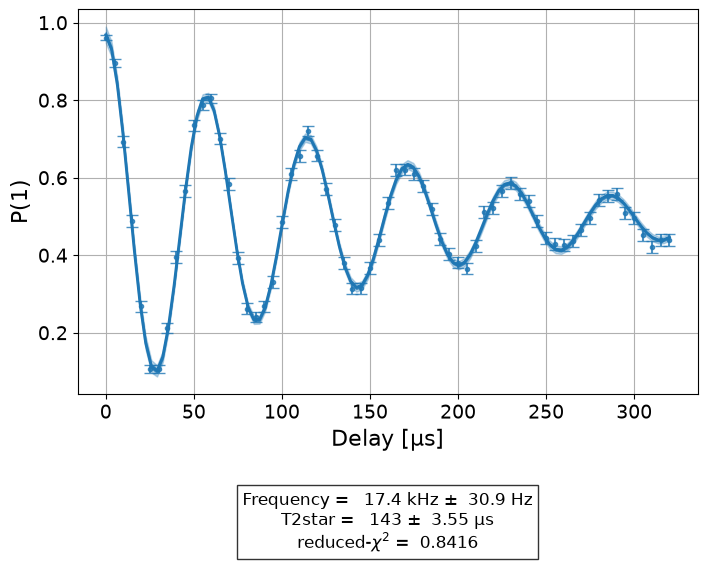

,name,value,chisq,quality
79531b80,freq,-7612+/-21,1.101022,bad


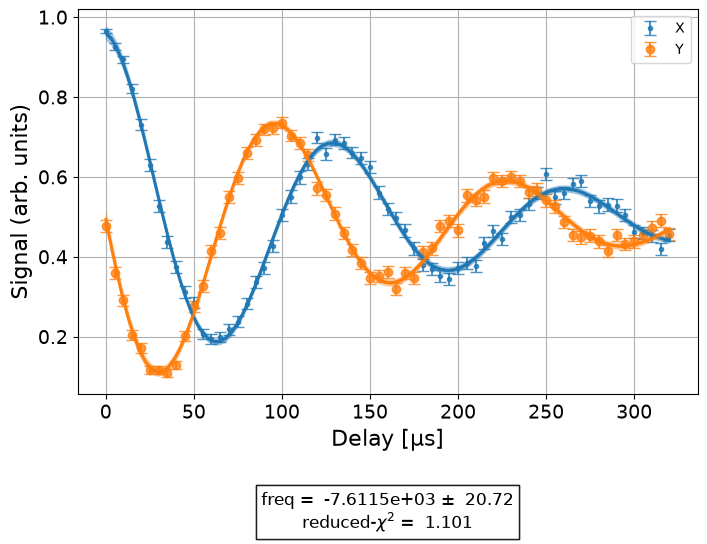

In [4]:
idle_model = (true_calibration_hz, true_t1_s, true_t2_s)

t2_exp = T2Ramsey(qubit, delays=sweep_delays, backend=aer, osc_freq=carrier_hz)
xy_exp = RamseyXY(qubit, backend=aer, delays=sweep_delays, osc_freq=0.0)


def run_characterization(experiment, idle_model, shots, simulation_seed):
    """Run the generated circuits in Aer and apply the experiment's own fit."""
    simulated = [add_simulated_idle(circuit, *idle_model)
                 for circuit in experiment.circuits()]
    compiled = transpile(simulated, aer, optimization_level=0, num_processes=1)
    result = aer.run(compiled, shots=shots, seed_simulator=simulation_seed).result()
    data = ExperimentData(experiment=experiment)
    data.add_data(result)
    return experiment.analysis.run(data).block_for_results()


t2_result = run_characterization(t2_exp, idle_model, calibration_shots, seed)
xy_result = run_characterization(xy_exp, idle_model, calibration_shots, seed + 1)

for title, result in (("T2Ramsey", t2_result), ("RamseyXY", xy_result)):
    print(title)
    display(result.analysis_results(dataframe=True)[["name", "value", "chisq", "quality"]])
    display(result.figure(0))

In [5]:
def fit_value(result, name):
    rows = result.analysis_results(dataframe=True)
    values = rows.loc[rows["name"] == name, "value"]
    if len(values) != 1:
        raise ValueError(f"Expected one fitted result named {name!r}.")
    return float(values.iloc[0].nominal_value)


estimated_t2_s = fit_value(t2_result, "T2star")
estimated_t2_detuning_hz = fit_value(t2_result, "Frequency") - carrier_hz
estimated_xy_detuning_hz = fit_value(xy_result, "freq")

display(pd.DataFrame({
    "Quantity": ["T2* (µs)", "Detuning (kHz)", "Detuning (kHz)"],
    "Protocol": ["T2Ramsey", "T2Ramsey with ramp removed", "RamseyXY"],
    "Estimate": [1e6 * estimated_t2_s, estimated_t2_detuning_hz / 1e3,
                 estimated_xy_detuning_hz / 1e3],
    "Simulation truth": [1e6 * true_t2_s, true_calibration_hz / 1e3,
                         true_calibration_hz / 1e3],
}).round(3))

,Quantity,Protocol,Estimate,Simulation truth
0,T2* (µs),T2Ramsey,142.527,145.0
1,Detuning (kHz),T2Ramsey with ramp removed,-7.561,-7.6
2,Detuning (kHz),RamseyXY,-7.612,-7.6


**Reading the quality flag.** In Qiskit Experiments 0.14.2, the RamseyXY quality check compares the frequency standard error to the signed fitted frequency. A finite nonnegative standard error cannot pass that comparison when the fitted frequency is negative. The negative-detuning example above therefore keeps the reported `bad` flag visible. Inspect the two plotted fits, their reduced chi-square, and the uncertainty relative to the **magnitude** of the frequency. In this simulation you can also compare with the known truth.

## 4. Convert RamseyXY counts to a frequency likelihood

Consider one tracking block. For a candidate detuning $f$ and wait $\tau$, write $\theta=2\pi f\tau$ and $v(\tau)=\exp(-\tau/\widehat T_2^*)$. The ideal readout probabilities for the two generated circuits are

$$
p^{\mathrm{ideal}}_{1,X}=\frac{1+v(\tau)\cos\theta}{2},
\qquad
p^{\mathrm{ideal}}_{1,Y}=\frac{1+v(\tau)\sin\theta}{2}.
$$

The $X$ and $Y$ labels follow Qiskit Experiments. The notebook checks these signs at four known phases using the ideal circuits, before taking noisy shots. With readout errors $e_{01}=P(\text{report }1\mid0)$ and $e_{10}=P(\text{report }0\mid1)$, the probability of recording a one becomes

$$
p_{1}=e_{01}+(1-e_{01}-e_{10})p^{\mathrm{ideal}}_{1}.
$$

For each setting $j$, the measured number of ones $k_j$ has a binomial distribution with size $n_j$ and probability $p_{1,j}(f)$. Conditional on $f$, the likelihood is the product of these terms across settings. We compute it on a grid and omit the binomial coefficients because they are constant in $f$. The fitted decay time is held fixed in this teaching example.

In [6]:
def phase_probe(circuit, angle):
    """Evaluate P(1) after inserting an ideal phase at the delay."""
    check = circuit.copy_empty_like()
    for item in circuit.data:
        if item.operation.name == "delay":
            check.rz(angle, 0)
        elif item.operation.name not in {"measure", "barrier"}:
            check.append(item.operation, [0])
    return Statevector.from_instruction(check).probabilities()[1]


settings = pd.DataFrame([c.metadata for c in tracking_circuits])
angles = np.arange(4) * np.pi / 2
for circuit in tracking_circuits:
    quadrature = {"X": np.cos, "Y": np.sin}[circuit.metadata["series"]]
    observed = [phase_probe(circuit, angle) for angle in angles]
    np.testing.assert_allclose(observed, (1 + quadrature(angles)) / 2, atol=1e-12)

display(settings.assign(wait_us=1e6 * settings["xval"])[["wait_us", "series"]])
print("The generated circuits match the four ideal phase checks.")

The generated circuits match the four ideal phase checks.


,wait_us,series
0,30.0,X
1,30.0,Y
2,120.0,X
3,120.0,Y


In [7]:
# Chosen search range based on the lab's expected residual detuning.
grid_hz = np.linspace(-15_000, 15_000, 1201)
wait_s = settings["xval"].to_numpy()
x_series = settings["series"].to_numpy() == "X"
phase_grid = 2 * np.pi * wait_s[:, None] * grid_hz[None, :]
quadrature_grid = np.where(x_series[:, None], np.cos(phase_grid), np.sin(phase_grid))
visibility = np.exp(-wait_s / estimated_t2_s)
ideal_p1 = (1 + visibility[:, None] * quadrature_grid) / 2
p1_grid = p_one_given_zero + (1 - p_one_given_zero - p_zero_given_one) * ideal_p1


def setting_log_likelihood(ones, totals):
    return (
        xlogy(ones[:, None], p1_grid)
        + xlog1py((totals - ones)[:, None], -p1_grid)
    )

## 5. Track drift with repeated blocks

Each block repeats the same two waits and two quadratures. The synthetic device wanders according to a Gaussian random walk between blocks. The analyst uses a random-walk **prior model** with a prespecified scale of 650 Hz per block and starts with a uniform prior over the 30 kHz grid. A lab could estimate the transition scale from past data. The notebook fixes it before filtering and never supplies the simulated trajectory to the filter.

The filter alternates two steps. First, predict the next frequency by spreading the previous posterior according to the transition model. Then multiply that prediction by the latest likelihood and normalize. A grid keeps the full posterior, so ambiguity between several fringes can remain visible.

Here the long-wait pair repeats every $1/(120\,\mu\mathrm{s})\approx8.33$ kHz. Adding the short-wait pair extends the exact repeat period to $33.33$ kHz. The plot compares a long-wait-only posterior with the four-setting posterior from the **same measured block**. It also shows the filtered trajectory and pointwise 90% credible intervals.

In [8]:
blocks = 32
assumed_step_hz = 650.0
rng = np.random.default_rng(seed)

# Truth for the simulator only. It begins offset from the earlier calibration.
true_track_hz = -3_400.0 + np.r_[0, np.cumsum(rng.normal(0, 730, blocks - 1))]

simulated_circuits = [
    add_simulated_idle(circuit, detuning, true_t1_s, true_t2_s)
    for detuning in true_track_hz
    for circuit in tracking_circuits
]
compiled = transpile(simulated_circuits, aer, optimization_level=0, num_processes=1)
raw_counts = aer.run(
    compiled, shots=tracking_shots, seed_simulator=seed + 2
).result().get_counts()

shape = (blocks, len(tracking_circuits))
ones = np.array([counts.get("1", 0) for counts in raw_counts]).reshape(shape)
totals = np.array([sum(counts.values()) for counts in raw_counts]).reshape(shape)
assert np.all(totals == tracking_shots)
display(settings.assign(ones=ones[0], shots=totals[0]))

,series,xval,ones,shots
0,X,0.00003,199,256
1,Y,0.00003,82,256
2,X,0.00012,95,256
3,Y,0.00012,82,256


Tracking RMSE on this simulated trajectory: 177 Hz.
The 90% intervals contained the simulated truth in 27/32 blocks.


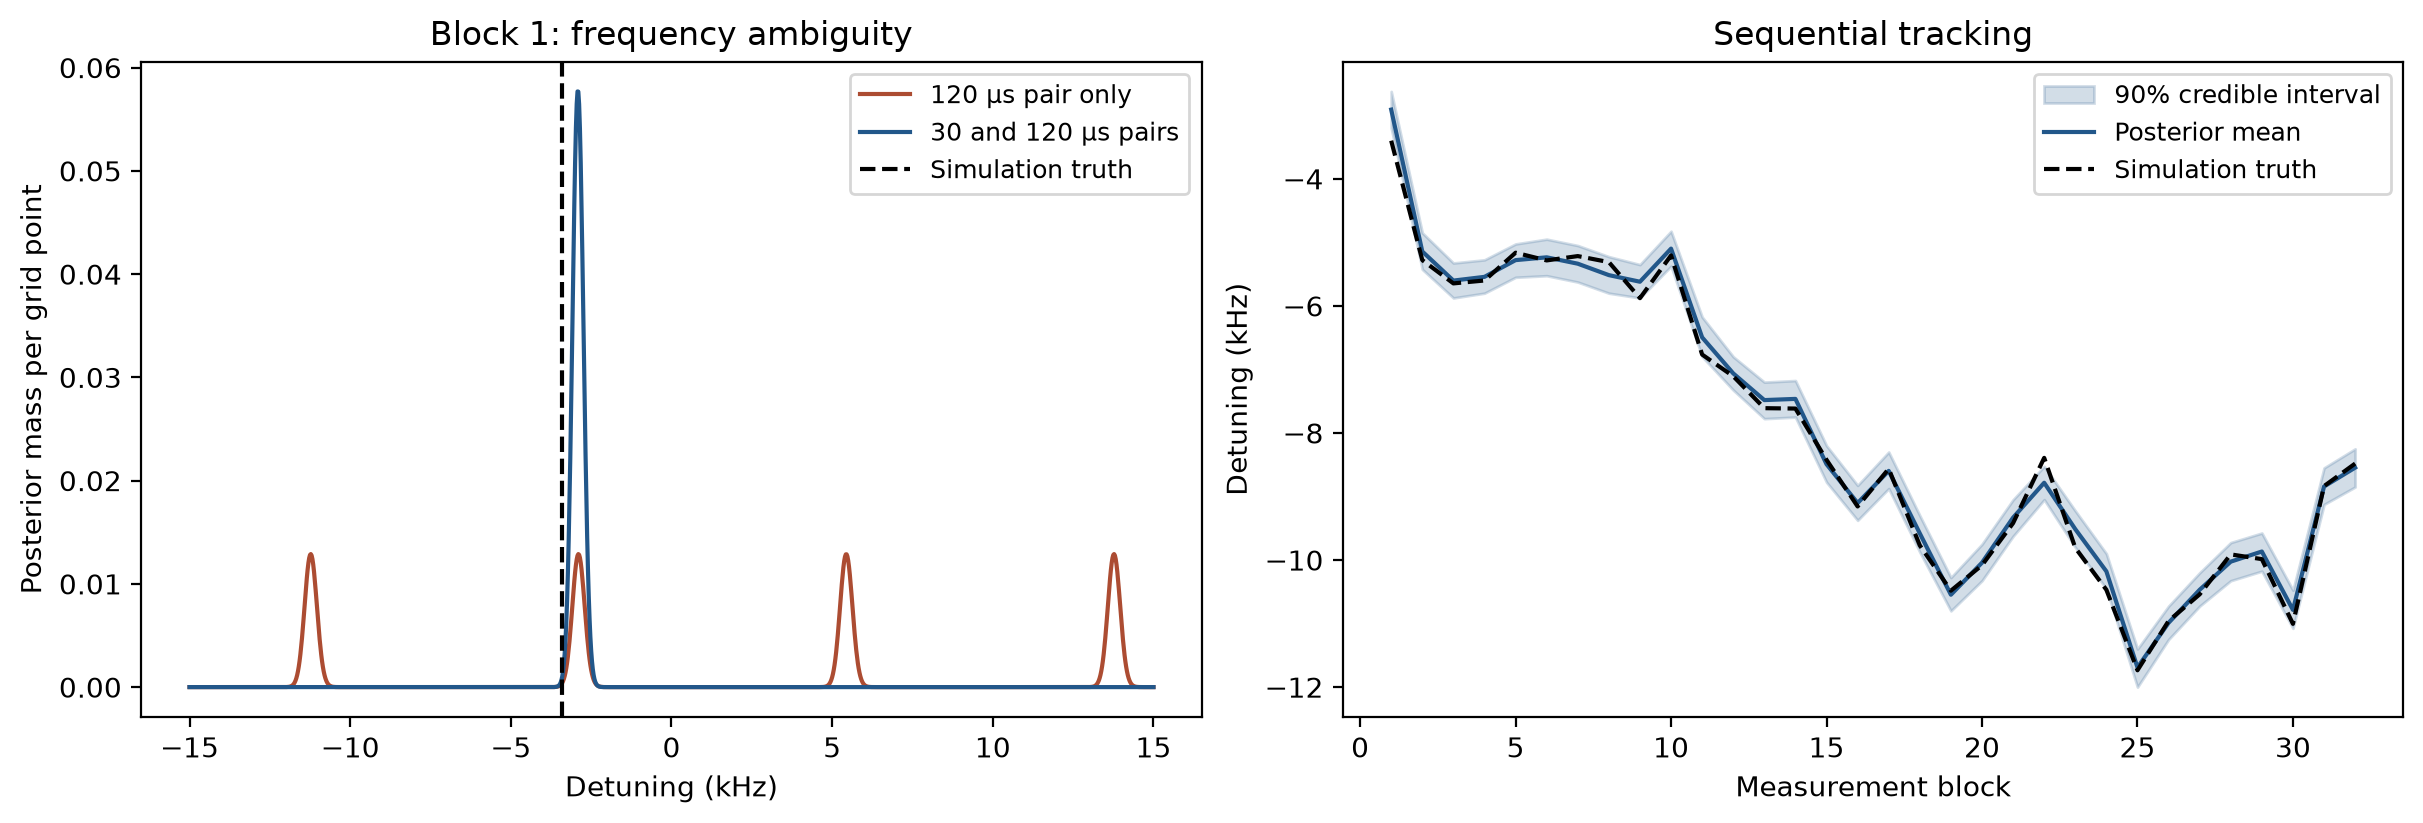

In [9]:
def normalized_mass(log_mass):
    return np.exp(log_mass - logsumexp(log_mass))


# Column j is P(next grid frequency | current grid point j).
# Renormalization on the finite grid gives a truncated transition.
increments = grid_hz[:, None] - grid_hz[None, :]
transition = np.exp(-0.5 * (increments / assumed_step_hz) ** 2)
transition /= transition.sum(axis=0)

prior = np.full(grid_hz.size, 1 / grid_hz.size)
posterior = np.empty((blocks, grid_hz.size))
for block, (block_ones, block_totals) in enumerate(zip(ones, totals)):
    if block:
        prior = transition @ posterior[block - 1]
    log_likelihood = setting_log_likelihood(block_ones, block_totals)
    posterior[block] = normalized_mass(np.log(prior) + log_likelihood.sum(axis=0))

first_likelihood = setting_log_likelihood(ones[0], totals[0])
long_settings = np.isclose(wait_s, max(wait_s))
long_only = normalized_mass(first_likelihood[long_settings].sum(axis=0))

mean_hz = posterior @ grid_hz
cdf = posterior.cumsum(axis=1)
lower_hz = grid_hz[(cdf >= 0.05).argmax(axis=1)]
upper_hz = grid_hz[(cdf >= 0.95).argmax(axis=1)]
rmse_hz = np.sqrt(np.mean((mean_hz - true_track_hz) ** 2))

fig, (ax_posterior, ax_track) = plt.subplots(
    1, 2, figsize=(12, 4), layout="constrained"
)
ax_posterior.plot(grid_hz / 1e3, long_only, label="120 µs pair only", color="#ac4c32")
ax_posterior.plot(grid_hz / 1e3, posterior[0], label="30 and 120 µs pairs", color="#22578a")
ax_posterior.axvline(true_track_hz[0] / 1e3, color="black", ls="--", label="Simulation truth")
ax_posterior.set(xlabel="Detuning (kHz)", ylabel="Posterior mass per grid point",
                 title="Block 1: frequency ambiguity")
ax_posterior.legend(fontsize=9)

index = np.arange(1, blocks + 1)
ax_track.fill_between(index, lower_hz / 1e3, upper_hz / 1e3, color="#22578a",
                      alpha=0.20, label="90% credible interval")
ax_track.plot(index, mean_hz / 1e3, color="#22578a", label="Posterior mean")
ax_track.plot(index, true_track_hz / 1e3, "k--", label="Simulation truth")
ax_track.set(xlabel="Measurement block", ylabel="Detuning (kHz)", title="Sequential tracking")
ax_track.legend(fontsize=9)
plt.show()

covered = np.count_nonzero((lower_hz <= true_track_hz) & (true_track_hz <= upper_hz))
print(f"Tracking RMSE on this simulated trajectory: {rmse_hz:.0f} Hz.")
print(f"The 90% intervals contained the simulated truth in {covered}/{blocks} blocks.")

## 6. From Aer to an IBM device

The **unmodified** experiment circuits are the starting point for hardware. Construct `T2Ramsey` or `RamseyXY` with a real backend and a selected physical qubit, so the circuit generator can account for device timing. The physical delay already accumulates the device's detuning and experiences decoherence. The two simulation-only operations added in Section 2 are specific to Aer. A programmed analysis ramp is still a valid circuit control. Use the executed delay values in the likelihood if the backend rounds them.

For a hardware characterization run, sweep the delays to check the contrast and the fit. For a tracking run, choose waits that give usable contrast, measure short and long quadratures within each block, and retain block timestamps. With irregular block spacing, the transition variance can be made a function of elapsed time. The RMSE and interval counts above describe one reproducible synthetic trajectory. Estimating tracking performance or coverage requires repeated runs.

**Try it**

1. Change the calibration detuning from negative to positive. Which outputs change sign? How does the programmed ramp enter the single-quadrature estimate?
2. Reduce the tracking shots to 32 per setting. Where do the credible intervals widen, and does the first block still distinguish the competing fringes?
3. Change the long wait and rerun. Compare $1/\tau$ and $e^{-\tau/\widehat T_2^*}$ for the old and new waits. How do alias spacing and coherence each affect the posterior?
4. Derive the readout correction by conditioning on the ideal bit. What happens to the baseline if $e_{01}\ne e_{10}$?

**Documentation**

- [Qiskit Experiments RamseyXY](https://qiskit-community.github.io/qiskit-experiments/stubs/qiskit_experiments.library.characterization.RamseyXY.html)
- [Qiskit Experiments T2* Ramsey characterization](https://qiskit-community.github.io/qiskit-experiments/manuals/characterization/t2ramsey.html)
- [IBM Quantum Sampler quickstart](https://quantum.cloud.ibm.com/docs/en/ibm-quantum-compute/get-started-with-sampler)